# Лабораторная работа №2


In [17]:
%pip install -q openpyxl

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 120})
pd.set_option("display.max_columns", 20)



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Общие функции


In [18]:
def train_validation_test_indices(sample_count, validation_fraction=0.2,
                                  test_fraction=0.2, seed=8055, stratify=None):

    generator = np.random.default_rng(seed)
    if stratify is None:
        groups = [np.arange(sample_count)]
    else:
        stratify = np.asarray(stratify)
        groups = [np.flatnonzero(stratify == label) for label in np.unique(stratify)]

    train_parts, validation_parts, test_parts = [], [], []
    for group in groups:
        indices = generator.permutation(group)
        test_count = int(np.ceil(len(group) * test_fraction))
        validation_count = int(np.ceil(len(group) * validation_fraction))
        test_parts.append(indices[:test_count])
        validation_parts.append(indices[test_count:test_count + validation_count])
        train_parts.append(indices[test_count + validation_count:])

    return tuple(generator.permutation(np.concatenate(parts))
                 for parts in [train_parts, validation_parts, test_parts])


## Предобработка


In [19]:
def prepare_features(train_features, validation_features, test_features,
                     numeric_columns, categorical_columns,
                     scaling=True, drop_first=True):
    medians = train_features[numeric_columns].median().fillna(0.0)
    numeric_parts = [
        frame[numeric_columns].fillna(medians).to_numpy(dtype=float)
        for frame in [train_features, validation_features, test_features]
    ]
    means = numeric_parts[0].mean(axis=0)
    deviations = numeric_parts[0].std(axis=0)
    deviations[deviations == 0] = 1.0
    if scaling:
        numeric_parts = [(part - means) / deviations for part in numeric_parts]

    parts = [[part] for part in numeric_parts]
    feature_names = list(numeric_columns)
    frames = [train_features, validation_features, test_features]
    for column in categorical_columns:
        values = [frame[column].astype("string").fillna("Unknown") for frame in frames]
        categories = sorted(values[0].unique())
        if drop_first:
            categories = categories[1:]
        for category in categories:
            feature_names.append(f"{column}={category}")
            for part, column_values in zip(parts, values):
                part.append((column_values == category).to_numpy(dtype=float))

    arrays = [np.column_stack(part) for part in parts]
    return (*arrays, feature_names)


def describe_data(data, target):
    print("Размер:", data.shape)
    print("Дубликатов:", data.duplicated().sum())
    display(data.head())
    display(pd.DataFrame({
        "Тип": data.dtypes.astype(str),
        "Пропуски": data.isna().sum(),
        "Уникальных": data.nunique(),
    }))
    if pd.api.types.is_numeric_dtype(data[target]) and data[target].nunique() > 10:
        display(data[target].describe().to_frame())
    else:
        display(data[target].value_counts().to_frame("Количество"))


## Метрики


In [20]:
def mean_absolute_error(targets, predictions):
    return np.mean(np.abs(np.asarray(predictions) - np.asarray(targets)))


def mean_squared_error(targets, predictions):
    return np.mean((np.asarray(predictions) - np.asarray(targets)) ** 2)


def root_mean_squared_error(targets, predictions):
    return mean_squared_error(targets, predictions) ** 0.5


def coefficient_of_determination(targets, predictions):
    residual_sum = np.sum((targets - predictions) ** 2)
    total_sum = np.sum((targets - np.mean(targets)) ** 2)
    return 1 - residual_sum / total_sum if total_sum != 0 else np.nan


def confusion_matrix(targets, predictions, labels=None):
    targets, predictions = np.asarray(targets), np.asarray(predictions)
    if labels is None:
        labels = np.unique(np.concatenate([targets, predictions]))
    return np.array([
        [np.sum((targets == actual) & (predictions == predicted))
         for predicted in labels]
        for actual in labels
    ])


def accuracy(targets, predictions):
    return np.mean(np.asarray(targets) == np.asarray(predictions))


def precision(targets, predictions):
    true_positive = np.sum((targets == 1) & (predictions == 1))
    predicted_positive = np.sum(predictions == 1)
    return true_positive / predicted_positive if predicted_positive else 0.0


def recall(targets, predictions):
    true_positive = np.sum((targets == 1) & (predictions == 1))
    actual_positive = np.sum(targets == 1)
    return true_positive / actual_positive if actual_positive else 0.0


def f1_score(targets, predictions):
    precision_value = precision(targets, predictions)
    recall_value = recall(targets, predictions)
    denominator = precision_value + recall_value
    return 2 * precision_value * recall_value / denominator if denominator else 0.0


def macro_f1_score(targets, predictions, labels=None):
    matrix = confusion_matrix(targets, predictions, labels)
    true_positive = np.diag(matrix)
    denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
    scores = np.divide(2 * true_positive, denominator,
                       out=np.zeros(len(matrix), dtype=float), where=denominator != 0)
    return np.mean(scores)


def log_loss(targets, probabilities):
    epsilon = np.finfo(float).eps
    probabilities = np.clip(probabilities, epsilon, 1 - epsilon)
    return -np.mean(targets * np.log(probabilities)
                    + (1 - targets) * np.log1p(-probabilities))


def regression_metrics(targets, predictions):
    return {
        "MAE": mean_absolute_error(targets, predictions),
        "RMSE": root_mean_squared_error(targets, predictions),
        "R^2": coefficient_of_determination(targets, predictions),
    }


def binary_metrics(targets, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "Accuracy": accuracy(targets, predictions),
        "Precision": precision(targets, predictions),
        "Recall": recall(targets, predictions),
        "F1": f1_score(targets, predictions),
        "LogLoss": log_loss(targets, probabilities),
    }


## Регуляризация


In [21]:
def regularization_penalty(weights, regularization, strength, l1_ratio=0.5):
    if regularization == "none":
        return 0.0
    l1 = np.sum(np.abs(weights))
    l2 = np.sum(weights ** 2) / 2
    if regularization == "l1":
        return strength * l1
    if regularization == "l2":
        return strength * l2
    if regularization == "elasticnet":
        return strength * (l1_ratio * l1 + (1 - l1_ratio) * l2)


def regularization_gradient(weights, regularization, strength, l1_ratio=0.5):
    if regularization == "none":
        return np.zeros_like(weights)
    if regularization == "l1":
        return strength * np.sign(weights)
    if regularization == "l2":
        return strength * weights
    if regularization == "elasticnet":
        return strength * (l1_ratio * np.sign(weights) + (1 - l1_ratio) * weights)


def sigmoid(values):
    result = np.empty_like(values, dtype=float)
    positive = values >= 0
    result[positive] = 1 / (1 + np.exp(-values[positive]))
    exponent = np.exp(values[~positive])
    result[~positive] = exponent / (1 + exponent)
    return result


## Модели


In [22]:
class LinearRegression:
    def __init__(self, learning_rate=0.03, epochs=100, regularization="none",
                 strength=0.0, l1_ratio=0.5):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.regularization = regularization
        self.strength = strength
        self.l1_ratio = l1_ratio
        self.weights = None
        self.bias = 0.0
        self.history = []
        self.objective_history = []

    def fit(self, features, targets):
        self.weights = np.zeros(features.shape[1])
        self.bias = 0.0
        self.history = []
        self.objective_history = []

        for epoch in range(self.epochs):
            predictions = features @ self.weights + self.bias
            errors = predictions - targets
            weights_gradient = 2 / len(targets) * (features.T @ errors)
            weights_gradient += regularization_gradient(
                self.weights, self.regularization, self.strength, self.l1_ratio)
            bias_gradient = 2 * np.mean(errors)

            self.weights -= self.learning_rate * weights_gradient
            self.bias -= self.learning_rate * bias_gradient

            loss = mean_squared_error(targets, features @ self.weights + self.bias)
            penalty = regularization_penalty(
                self.weights, self.regularization, self.strength, self.l1_ratio)
            self.history.append(loss)
            self.objective_history.append(loss + penalty)

        return self

    def predict(self, features):
        return features @ self.weights + self.bias


class LogisticRegression:
    def __init__(self, learning_rate=0.1, epochs=100, threshold=0.5,
                 regularization="none", strength=0.0, l1_ratio=0.5):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.threshold = threshold
        self.regularization = regularization
        self.strength = strength
        self.l1_ratio = l1_ratio
        self.weights = None
        self.bias = 0.0
        self.history = []
        self.objective_history = []

    def fit(self, features, targets):
        self.weights = np.zeros(features.shape[1])
        self.bias = 0.0
        self.history = []
        self.objective_history = []

        for epoch in range(self.epochs):
            logits = features @ self.weights + self.bias
            probabilities = sigmoid(logits)
            errors = probabilities - targets
            weights_gradient = features.T @ errors / len(targets)
            weights_gradient += regularization_gradient(
                self.weights, self.regularization, self.strength, self.l1_ratio)
            bias_gradient = np.mean(errors)

            self.weights -= self.learning_rate * weights_gradient
            self.bias -= self.learning_rate * bias_gradient

            logits = features @ self.weights + self.bias
            loss = np.mean(np.logaddexp(0, logits) - targets * logits)
            penalty = regularization_penalty(
                self.weights, self.regularization, self.strength, self.l1_ratio)
            self.history.append(loss)
            self.objective_history.append(loss + penalty)

        return self

    def predict_proba(self, features):
        return sigmoid(features @ self.weights + self.bias)

    def predict(self, features):
        return (self.predict_proba(features) >= self.threshold).astype(int)


### KNN


In [23]:
class KNN:
    def __init__(self, k=5, task="classification", distance="euclidean", batch_size=128):
        self.k = k
        self.task = task
        self.distance = distance
        self.batch_size = batch_size
        self.features = None

    def fit(self, features, targets):
        features, targets = np.asarray(features, dtype=float), np.asarray(targets)
        if self.task == "regression":
            targets = targets.astype(float)
        self.features = features.copy()
        self.targets = targets.copy()
        if self.task == "classification":
            self.classes, self.encoded_targets = np.unique(targets, return_inverse=True)
        return self

    def _distances(self, queries):
        distances = np.zeros((len(queries), len(self.features)))
        for column in range(self.features.shape[1]):
            difference = queries[:, column, None] - self.features[None, :, column]
            if self.distance == "euclidean":
                distances += difference ** 2
            else:
                distances += np.abs(difference)
        return np.sqrt(distances) if self.distance == "euclidean" else distances

    def _aggregate(self, neighbor_indices):
        if self.task == "regression":
            return self.targets[neighbor_indices].mean(axis=1)
        neighbor_labels = self.encoded_targets[neighbor_indices]
        votes = np.column_stack([
            np.sum(neighbor_labels == label, axis=1) for label in range(len(self.classes))
        ])
        return self.classes[np.argmax(votes, axis=1)]

    def predict_many(self, features, k_values):
        features = np.asarray(features, dtype=float)
        k_values = list(k_values)
        results = {k: [] for k in k_values}
        for start in range(0, len(features), self.batch_size):
            distances = self._distances(features[start:start + self.batch_size])
            neighbors = np.argsort(distances, axis=1, kind="stable")[:, :max(k_values)]
            for k in k_values:
                results[k].append(self._aggregate(neighbors[:, :k]))
        return {k: np.concatenate(parts)
                for k, parts in results.items()}

    def predict(self, features):
        return self.predict_many(features, [self.k])[self.k]


## Функции для экспериментов


In [24]:
def select_regularization(model_class, train_features, train_targets,
                          validation_features, validation_targets,
                          learning_rate, epochs=100):
    strengths = [0.0001, 0.001, 0.01, 0.1, 1.0]
    selected, rows = {}, []
    is_regression = model_class is LinearRegression
    for name in ["none", "l1", "l2", "elasticnet"]:
        best_score = np.inf
        candidates = [0.0] if name == "none" else strengths
        ratios = [0.25, 0.5, 0.75] if name == "elasticnet" else [0.5]
        for strength in candidates:
            for ratio in ratios:
                model = model_class(learning_rate=learning_rate, epochs=epochs,
                                    regularization=name, strength=strength, l1_ratio=ratio)
                model.fit(train_features, train_targets)
                if is_regression:
                    score = root_mean_squared_error(
                        validation_targets, model.predict(validation_features))
                else:
                    score = log_loss(validation_targets,
                                     model.predict_proba(validation_features))
                rows.append({"Модель": name, "lambda": strength,
                             "l1_ratio": ratio if name == "elasticnet" else np.nan,
                             "Validation loss": score})
                if score < best_score:
                    best_score = score
                    selected[name] = model
    return selected, pd.DataFrame(rows)


def plot_regularization(models, title, ylabel):
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    baseline = np.asarray(models["none"].history)
    styles = ["-", "--", "-.", ":"]
    markers = ["o", "s", "^", "D"]

    for index, (name, model) in enumerate(models.items()):
        epochs = np.arange(1, len(model.history) + 1)
        history = np.asarray(model.history)
        for axis, values in zip(axes, [history, history - baseline]):
            axis.plot(epochs, values, label=name, color=f"C{index}",
                      linestyle=styles[index], marker=markers[index],
                      markevery=(index, 500), markersize=4, linewidth=1.6)

    axes[0].set_title("Ошибка на train")
    axes[0].set_ylabel(ylabel)
    axes[1].set_title("Разница с none")
    axes[1].set_ylabel("Ошибка модели − ошибка none")
    axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)
    for axis in axes:
        axis.set_xlabel("Эпоха")
        axis.set_xlim(1, len(baseline))
        axis.legend()
        axis.grid(alpha=0.25)
    figure.suptitle(title)
    figure.tight_layout()
    plt.show()


def weights_summary(models, feature_names, threshold=0.001):
    rows = []
    for name, model in models.items():
        rows.append({"Модель": name, "lambda": model.strength,
                     "l1_ratio": model.l1_ratio if name == "elasticnet" else np.nan,
                     "L1 норма": np.sum(np.abs(model.weights)),
                     "L2 норма": np.linalg.norm(model.weights),
                     "Почти нулевых": np.sum(np.abs(model.weights) < threshold),
                     "Всего весов": len(model.weights)})
    table = pd.DataFrame(rows).set_index("Модель")
    coefficients = pd.DataFrame({name: model.weights for name, model in models.items()},
                                index=feature_names)
    return table, coefficients


def select_knn(feature_sets, train_targets, validation_targets, task,
               k_values=(1, 3, 5, 7, 11, 15, 21, 31)):
    rows, selected = [], {}
    for scaling, (train_features, validation_features, _) in feature_sets.items():
        for distance in ["euclidean", "manhattan"]:
            model = KNN(k=max(k_values), task=task, distance=distance)
            model.fit(train_features, train_targets)
            predictions_by_k = model.predict_many(validation_features, k_values)
            condition_rows = []
            for k, predictions in predictions_by_k.items():
                metrics = ({"Accuracy": accuracy(validation_targets, predictions),
                            "Macro F1": macro_f1_score(validation_targets, predictions)}
                           if task == "classification"
                           else regression_metrics(validation_targets, predictions))
                row = {"Scaling": scaling, "Distance": distance, "k": k, **metrics}
                rows.append(row)
                condition_rows.append(row)
            table = pd.DataFrame(condition_rows)
            if task == "classification":
                best = table.sort_values(["Macro F1", "Accuracy", "k"],
                                         ascending=[False, False, True]).iloc[0]
            else:
                best = table.sort_values(["RMSE", "k"]).iloc[0]
            model.k = int(best["k"])
            selected[(scaling, distance)] = model

    results = pd.DataFrame(rows)
    if task == "classification":
        best = results.sort_values(["Macro F1", "Accuracy", "k"],
                                   ascending=[False, False, True], kind="stable").iloc[0]
    else:
        best = results.sort_values(["RMSE", "k"], kind="stable").iloc[0]
    winner = (best["Scaling"], best["Distance"])
    return selected, results, winner


def plot_knn_validation(results, metric, title):
    plt.figure()
    for (scaling, distance), group in results.groupby(["Scaling", "Distance"]):
        plt.plot(group["k"], group[metric], marker="o", label=f"{scaling}; {distance}")
    plt.xlabel("k")
    plt.ylabel(f"Validation {metric}")
    plt.title(title)
    plt.legend(fontsize=8)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(targets, predictions, labels):
    matrix = confusion_matrix(targets, predictions, labels)
    figure, axis = plt.subplots(figsize=(8, 6))
    image = axis.imshow(matrix, cmap="Blues")
    figure.colorbar(image, ax=axis)
    axis.set_xticks(np.arange(len(labels)), labels=labels, rotation=45, ha="right")
    axis.set_yticks(np.arange(len(labels)), labels=labels)
    for row in range(len(labels)):
        for column in range(len(labels)):
            axis.text(column, row, str(matrix[row, column]), ha="center", va="center",
                      color="white" if matrix[row, column] > matrix.max() / 2 else "black")
    axis.set_xlabel("Прогноз")
    axis.set_ylabel("Истинный класс")
    axis.set_title("KNN: confusion matrix на test")
    plt.tight_layout()
    plt.show()


In [25]:
data_dir = Path("data")
bike_path = data_dir / "day.csv"
spaceship_path = data_dir / "train.csv"
bean_path = data_dir / "Dry_Bean_Dataset.xlsx"
seoul_path = data_dir / "SeoulBikeData.csv"


epochs = 8000
near_zero_threshold = 0.001


## A. Regularization
### Linear Regression
Target: `cnt`. Исключены `casual` и `registered`, поскольку `cnt = casual + registered`.


In [26]:
bike_data = pd.read_csv(bike_path)
describe_data(bike_data, "cnt")
display(bike_data[["cnt", "temp", "hum", "windspeed"]].describe().round(3))


Размер: (731, 16)
Дубликатов: 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,Тип,Пропуски,Уникальных
instant,int64,0,731
dteday,str,0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,3
temp,float64,0,499


,cnt
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


,cnt,temp,hum,windspeed
count,731.000,731.000,731.000,731.000
mean,4504.349,0.495,0.628,0.190
std,1937.211,0.183,0.142,0.077
min,22.000,0.059,0.000,0.022
25%,3152.000,0.337,0.520,0.135
50%,4548.000,0.498,0.627,0.181
75%,5956.000,0.655,0.730,0.233
max,8714.000,0.862,0.972,0.507


In [27]:
bike_features = bike_data.drop(columns=["cnt", "casual", "registered", "instant", "dteday"])
bike_targets = bike_data["cnt"].to_numpy(dtype=float)
bike_numeric_columns = ["yr", "holiday", "workingday", "temp", "atemp", "hum", "windspeed"]
bike_categorical_columns = ["season", "mnth", "weekday", "weathersit"]

bike_train_indices, bike_validation_indices, bike_test_indices = (
    train_validation_test_indices(len(bike_data)))
bike_train_targets = bike_targets[bike_train_indices]
bike_validation_targets = bike_targets[bike_validation_indices]
bike_test_targets = bike_targets[bike_test_indices]

bike_train_features, bike_validation_features, bike_test_features, bike_feature_names = (
    prepare_features(bike_features.iloc[bike_train_indices],
                     bike_features.iloc[bike_validation_indices],
                     bike_features.iloc[bike_test_indices],
                     bike_numeric_columns, bike_categorical_columns))

bike_target_mean = bike_train_targets.mean()
bike_target_deviation = bike_train_targets.std()
if bike_target_deviation == 0:
    bike_target_deviation = 1.0
bike_train_targets_scaled = (bike_train_targets - bike_target_mean) / bike_target_deviation
bike_validation_targets_scaled = (bike_validation_targets - bike_target_mean) / bike_target_deviation

print("Train:", bike_train_features.shape, "Validation:", bike_validation_features.shape,
      "Test:", bike_test_features.shape)


Train: (437, 29) Validation: (147, 29) Test: (147, 29)


,Модель,lambda,l1_ratio,Validation RMSE
0,none,0.0000,NaN,820.774961
1,l1,0.0001,NaN,820.932146
2,l1,0.0010,NaN,823.228480
3,l1,0.0100,NaN,856.527595
4,l1,0.1000,NaN,1048.725323
5,l1,1.0000,NaN,1836.549442
6,l2,0.0001,NaN,820.910601
7,l2,0.0010,NaN,822.193404
8,l2,0.0100,NaN,835.511236
9,l2,0.1000,NaN,901.007708


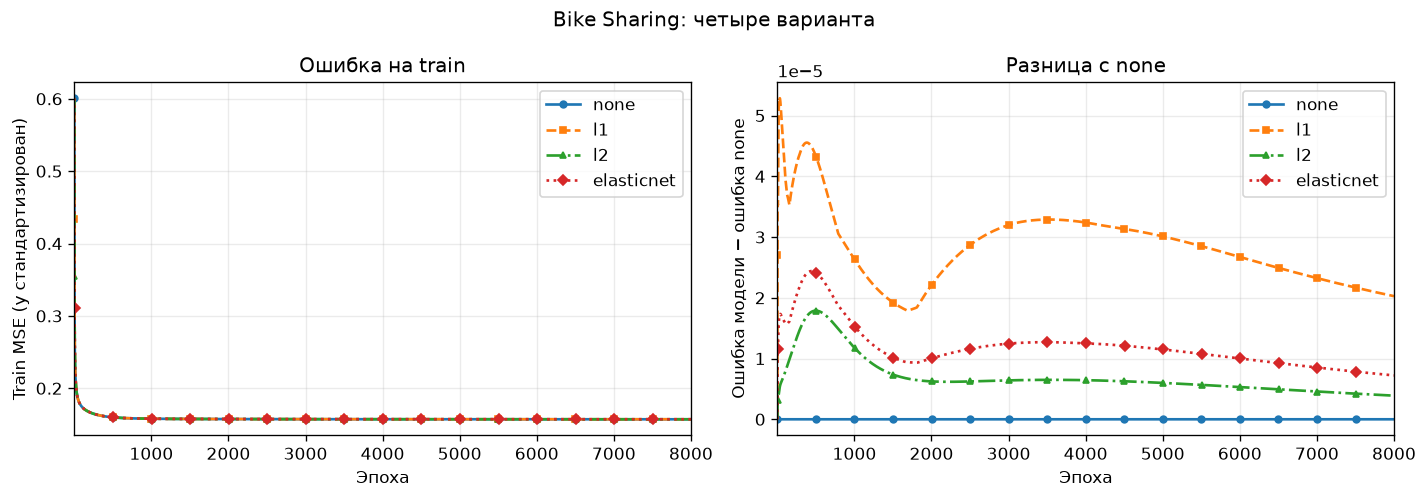

In [28]:
linear_models, linear_validation_results = select_regularization(
    LinearRegression, bike_train_features, bike_train_targets_scaled,
    bike_validation_features, bike_validation_targets_scaled, learning_rate=0.1, epochs=epochs)
linear_validation_results["Validation RMSE"] = (
    linear_validation_results.pop("Validation loss") * bike_target_deviation)
display(linear_validation_results.round(6))

plot_regularization(linear_models, "Bike Sharing: четыре варианта", "Train MSE (y стандартизирован)")


In [29]:
bike_results = []
for name, model in linear_models.items():
    predictions = model.predict(bike_test_features) * bike_target_deviation + bike_target_mean
    validation_predictions = (model.predict(bike_validation_features)
                              * bike_target_deviation + bike_target_mean)
    bike_results.append({"Модель": name,
                         "Validation RMSE": root_mean_squared_error(
                             bike_validation_targets, validation_predictions),
                         **regression_metrics(bike_test_targets, predictions)})
bike_results = pd.DataFrame(bike_results).set_index("Модель")
display(bike_results.round(3))

linear_weights, linear_coefficients = weights_summary(
    linear_models, bike_feature_names, near_zero_threshold)
display(linear_weights.round(6))
display(linear_coefficients.round(6))

linear_winner = bike_results["Validation RMSE"].idxmin()
print(f"Вывод: по validation выбран {linear_winner}. "
      f"Его test RMSE = {bike_results.loc[linear_winner, 'RMSE']:.2f}; "
      f"без регуляризации = {bike_results.loc['none', 'RMSE']:.2f}.")


,Validation RMSE,MAE,RMSE,R^2
Модель,,,,
none,820.775,589.243,782.632,0.860
l1,820.932,588.921,780.074,0.861
l2,820.911,589.150,781.794,0.860
elasticnet,820.913,589.104,781.384,0.860


,lambda,l1_ratio,L1 норма,L2 норма,Почти нулевых,Всего весов
Модель,,,,,,
none,0.0000,NaN,7.413228,1.863881,0,29
l1,0.0001,NaN,7.022563,1.828079,0,29
l2,0.0001,NaN,7.337076,1.853125,0,29
elasticnet,0.0001,0.25,7.215624,1.845395,0,29


,none,l1,l2,elasticnet
yr,0.531469,0.531217,0.531388,0.531341
holiday,-0.003034,-0.010898,-0.003873,-0.006562
workingday,0.123990,0.102028,0.121811,0.114136
temp,-0.160332,-0.136498,-0.152805,-0.148771
atemp,0.603922,0.585834,0.598013,0.595034
hum,-0.124121,-0.124580,-0.124386,-0.124432
windspeed,-0.112091,-0.112358,-0.112259,-0.112287
season=2,0.459684,0.465015,0.460384,0.461523
season=3,0.293535,0.296583,0.293663,0.294323
season=4,0.738720,0.737751,0.738244,0.738085


Вывод: по validation выбран none. Его test RMSE = 782.63; без регуляризации = 782.63.


### Logistic Regression
Target: `Transported`. Порог: 0.5.


In [30]:
spaceship_data = pd.read_csv(spaceship_path)
describe_data(spaceship_data, "Transported")
display(spaceship_data[["Age", "RoomService", "FoodCourt", "Spa"]].describe().round(3))


Размер: (8693, 14)
Дубликатов: 0


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


,Тип,Пропуски,Уникальных
PassengerId,str,0,8693
HomePlanet,str,201,3
CryoSleep,object,217,2
Cabin,str,199,6560
Destination,str,182,3
Age,float64,179,80
VIP,object,203,2
RoomService,float64,181,1273
FoodCourt,float64,183,1507
ShoppingMall,float64,208,1115


,Количество
Transported,
True,4378
False,4315


,Age,RoomService,FoodCourt,Spa
count,8514.000,8512.000,8510.000,8510.000
mean,28.828,224.688,458.077,311.139
std,14.489,666.718,1611.489,1136.706
min,0.000,0.000,0.000,0.000
25%,19.000,0.000,0.000,0.000
50%,27.000,0.000,0.000,0.000
75%,38.000,47.000,76.000,59.000
max,79.000,14327.000,29813.000,22408.000


In [31]:
spaceship_features = spaceship_data.drop(columns=["Transported", "PassengerId", "Name", "Cabin"])
cabin = spaceship_data["Cabin"].str.split("/", expand=True)
spaceship_features["Deck"] = cabin[0]
spaceship_features["Side"] = cabin[2]
spaceship_targets = spaceship_data["Transported"].to_numpy(dtype=int)
spaceship_numeric_columns = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
spaceship_categorical_columns = ["HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side"]

spaceship_train_indices, spaceship_validation_indices, spaceship_test_indices = (
    train_validation_test_indices(len(spaceship_data), stratify=spaceship_targets))
spaceship_train_targets = spaceship_targets[spaceship_train_indices]
spaceship_validation_targets = spaceship_targets[spaceship_validation_indices]
spaceship_test_targets = spaceship_targets[spaceship_test_indices]

spaceship_train_features, spaceship_validation_features, spaceship_test_features, spaceship_feature_names = (
    prepare_features(spaceship_features.iloc[spaceship_train_indices],
                     spaceship_features.iloc[spaceship_validation_indices],
                     spaceship_features.iloc[spaceship_test_indices],
                     spaceship_numeric_columns, spaceship_categorical_columns))

display(pd.DataFrame({
    "Объектов": [len(spaceship_train_targets), len(spaceship_validation_targets), len(spaceship_test_targets)],
    "Доля класса 1": [spaceship_train_targets.mean(), spaceship_validation_targets.mean(), spaceship_test_targets.mean()],
}, index=["Train", "Validation", "Test"]).round(3))


,Объектов,Доля класса 1
Train,5215,0.504
Validation,1739,0.504
Test,1739,0.504


,Модель,lambda,l1_ratio,Validation LogLoss
0,none,0.0000,NaN,0.437080
1,l1,0.0001,NaN,0.436976
2,l1,0.0010,NaN,0.436741
3,l1,0.0100,NaN,0.462432
4,l1,0.1000,NaN,0.674123
5,l1,1.0000,NaN,0.676329
6,l2,0.0001,NaN,0.437152
7,l2,0.0010,NaN,0.438287
8,l2,0.0100,NaN,0.454486
9,l2,0.1000,NaN,0.539266


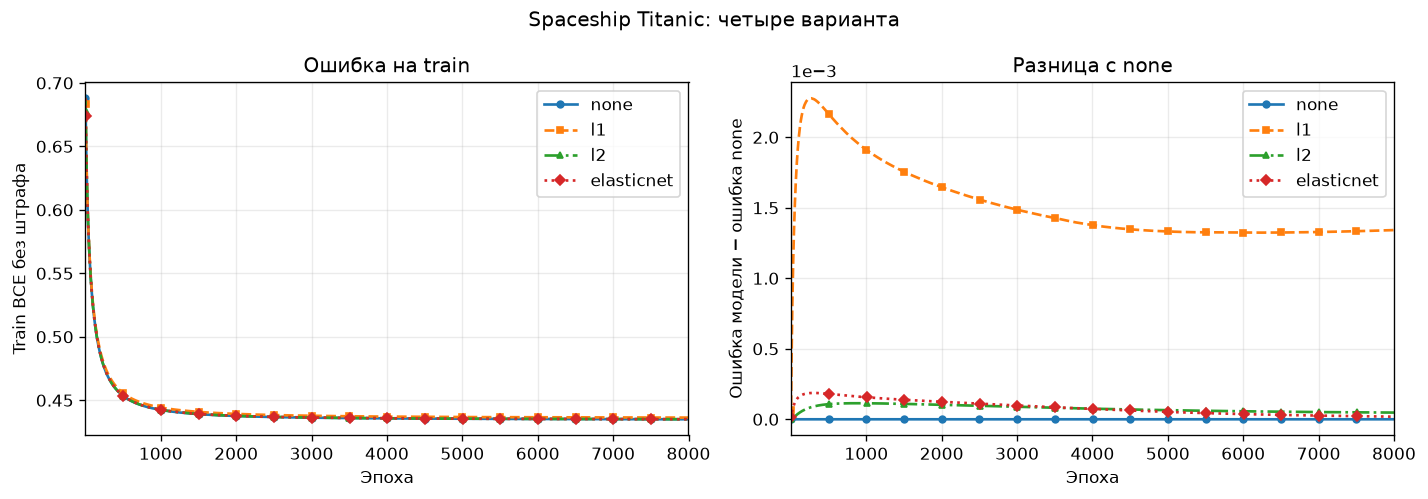

In [32]:
logistic_models, logistic_validation_results = select_regularization(
    LogisticRegression, spaceship_train_features, spaceship_train_targets,
    spaceship_validation_features, spaceship_validation_targets, learning_rate=0.1, epochs=epochs)
logistic_validation_results = logistic_validation_results.rename(columns={"Validation loss": "Validation LogLoss"})
display(logistic_validation_results.round(6))

plot_regularization(logistic_models, "Spaceship Titanic: четыре варианта", "Train BCE без штрафа")


In [33]:
spaceship_results = []
for name, model in logistic_models.items():
    probabilities = model.predict_proba(spaceship_test_features)
    validation_probabilities = model.predict_proba(spaceship_validation_features)
    spaceship_results.append({"Модель": name,
                              "Validation LogLoss": log_loss(spaceship_validation_targets,
                                                              validation_probabilities),
                              **binary_metrics(spaceship_test_targets, probabilities)})
spaceship_results = pd.DataFrame(spaceship_results).set_index("Модель")
display(spaceship_results.round(4))

logistic_weights, logistic_coefficients = weights_summary(
    logistic_models, spaceship_feature_names, near_zero_threshold)
display(logistic_weights.round(6))
display(logistic_coefficients.round(6))

logistic_winner = spaceship_results["Validation LogLoss"].idxmin()
print(f"Вывод: по validation выбран {logistic_winner}. "
      f"Его test LogLoss = {spaceship_results.loc[logistic_winner, 'LogLoss']:.4f}, "
      f"Accuracy = {spaceship_results.loc[logistic_winner, 'Accuracy']:.4f}. "
      f"Без регуляризации test LogLoss = {spaceship_results.loc['none', 'LogLoss']:.4f}.")


,Validation LogLoss,Accuracy,Precision,Recall,F1,LogLoss
Модель,,,,,,
none,0.4371,0.7999,0.8034,0.7979,0.8007,0.4302
l1,0.4367,0.7982,0.8042,0.7922,0.7982,0.4301
l2,0.4372,0.7999,0.8034,0.7979,0.8007,0.4301
elasticnet,0.4370,0.7999,0.8034,0.7979,0.8007,0.4301


,lambda,l1_ratio,L1 норма,L2 норма,Почти нулевых,Всего весов
Модель,,,,,,
none,0.0000,NaN,16.300901,4.504304,0,26
l1,0.0010,NaN,13.446400,4.059190,8,26
l2,0.0001,NaN,16.061088,4.438632,0,26
elasticnet,0.0001,0.75,15.863876,4.446193,1,26


,none,l1,l2,elasticnet
Age,-0.093369,-0.085811,-0.093684,-0.092946
RoomService,-1.058663,-1.003385,-1.051601,-1.052266
FoodCourt,0.817553,0.756621,0.808703,0.810842
ShoppingMall,0.303142,0.291441,0.302656,0.302160
Spa,-2.144165,-1.972957,-2.110036,-2.120209
VRDeck,-2.198331,-1.995031,-2.161096,-2.170601
HomePlanet=Europa,1.222168,1.291330,1.216765,1.232581
HomePlanet=Mars,0.606198,0.554184,0.601038,0.599366
HomePlanet=Unknown,0.216598,0.000125,0.210296,0.193650
CryoSleep=True,1.388346,1.361753,1.390140,1.387905


Вывод: по validation выбран l1. Его test LogLoss = 0.4301, Accuracy = 0.7982. Без регуляризации test LogLoss = 0.4302.


## B. KNN Classification
Target: `Class`.


In [34]:
bean_data = pd.read_excel(bean_path, engine="openpyxl")
describe_data(bean_data, "Class")
display(bean_data.drop(columns="Class").describe().round(3))

bean_duplicate_count = bean_data.duplicated().sum()
bean_data = bean_data.drop_duplicates().reset_index(drop=True)
print("Удалено полных дубликатов:", bean_duplicate_count)
print("После удаления:", bean_data.shape)


Размер: (13611, 17)
Дубликатов: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,Тип,Пропуски,Уникальных
Area,int64,0,12011
Perimeter,float64,0,13416
MajorAxisLength,float64,0,13543
MinorAxisLength,float64,0,13543
AspectRation,float64,0,13543
Eccentricity,float64,0,13543
ConvexArea,int64,0,12066
EquivDiameter,float64,0,12011
Extent,float64,0,13535
Solidity,float64,0,13526


,Количество
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000
mean,53048.285,855.283,320.142,202.271,1.583,0.751,53768.200,253.064,0.750,0.987,0.873,0.800,0.007,0.002,0.644,0.995
std,29324.096,214.290,85.694,44.970,0.247,0.092,29774.916,59.177,0.049,0.005,0.060,0.062,0.001,0.001,0.099,0.004
min,20420.000,524.736,183.601,122.513,1.025,0.219,20684.000,161.244,0.555,0.919,0.490,0.641,0.003,0.001,0.410,0.948
25%,36328.000,703.523,253.304,175.848,1.432,0.716,36714.500,215.068,0.719,0.986,0.832,0.762,0.006,0.001,0.581,0.994
50%,44652.000,794.941,296.883,192.432,1.551,0.764,45178.000,238.438,0.760,0.988,0.883,0.801,0.007,0.002,0.642,0.996
75%,61332.000,977.213,376.495,217.032,1.707,0.810,62294.000,279.446,0.787,0.990,0.917,0.834,0.007,0.002,0.696,0.998
max,254616.000,1985.370,738.860,460.198,2.430,0.911,263261.000,569.374,0.866,0.995,0.991,0.987,0.010,0.004,0.975,1.000


Удалено полных дубликатов: 68
После удаления: (13543, 17)


In [35]:
bean_features = bean_data.drop(columns="Class")
bean_targets = bean_data["Class"].to_numpy()
bean_numeric_columns = bean_features.columns.tolist()
bean_train_indices, bean_validation_indices, bean_test_indices = (
    train_validation_test_indices(len(bean_data), stratify=bean_targets))
bean_train_targets = bean_targets[bean_train_indices]
bean_validation_targets = bean_targets[bean_validation_indices]
bean_test_targets = bean_targets[bean_test_indices]

bean_feature_sets = {}
for scaling in [False, True]:
    train_features, validation_features, test_features, _ = prepare_features(
        bean_features.iloc[bean_train_indices], bean_features.iloc[bean_validation_indices],
        bean_features.iloc[bean_test_indices], bean_numeric_columns, [],
        scaling=scaling, drop_first=False)
    bean_feature_sets["Со scaling" if scaling else "Без scaling"] = (
        train_features, validation_features, test_features)

display(pd.DataFrame({
    name: pd.Series(values).value_counts() for name, values in [
        ("Train", bean_train_targets), ("Validation", bean_validation_targets), ("Test", bean_test_targets)]
}))


,Train,Validation,Test
DERMASON,2126,710,710
SIRA,1580,528,528
SEKER,1215,406,406
HOROZ,1116,372,372
CALI,978,326,326
BARBUNYA,792,265,265
BOMBAY,312,105,105


,Scaling,Distance,k,Accuracy,Macro F1
0,Без scaling,euclidean,1,0.7279,0.7332
1,Без scaling,euclidean,3,0.7220,0.7239
2,Без scaling,euclidean,5,0.7150,0.7181
3,Без scaling,euclidean,7,0.7113,0.7106
4,Без scaling,euclidean,11,0.7002,0.7017
5,Без scaling,euclidean,15,0.6932,0.6943
6,Без scaling,euclidean,21,0.6862,0.6870
7,Без scaling,euclidean,31,0.6726,0.6694
8,Без scaling,manhattan,1,0.7791,0.7857
9,Без scaling,manhattan,3,0.7858,0.7884


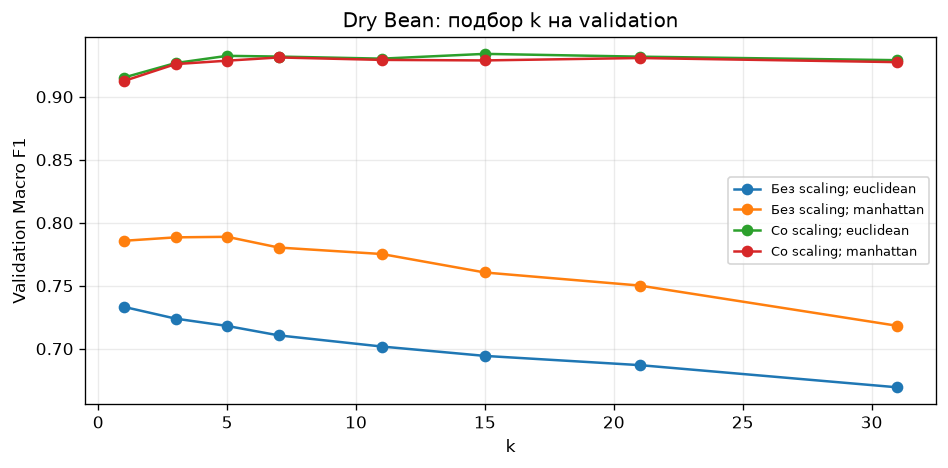

Выбрано по validation: ('Со scaling', 'euclidean') k = 15


In [36]:
bean_models, bean_validation_results, bean_winner = select_knn(
    bean_feature_sets, bean_train_targets, bean_validation_targets, task="classification")
display(bean_validation_results.round(4))
plot_knn_validation(bean_validation_results, "Macro F1", "Dry Bean: подбор k на validation")
print("Выбрано по validation:", bean_winner, "k =", bean_models[bean_winner].k)


k  Validation Macro F1  Test Accuracy  Test Macro F1
Scaling     Distance                                                        
Без scaling euclidean   1               0.7332         0.7286         0.7331
            manhattan   5               0.7888         0.7754         0.7755
Со scaling  euclidean  15               0.9340         0.9274         0.9396
            manhattan   7               0.9312         0.9270         0.9377

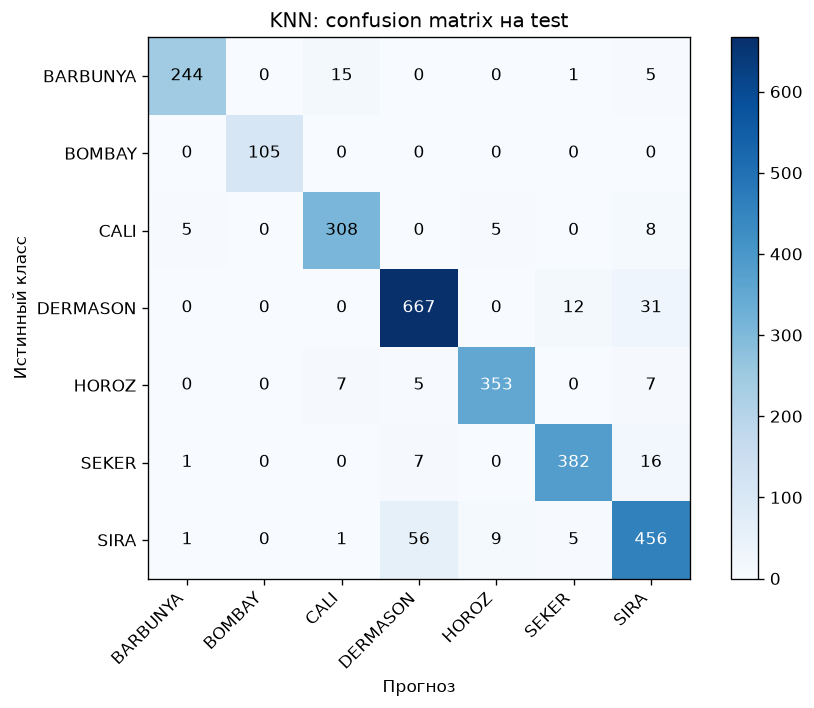

Вывод: по validation выбраны Со scaling, euclidean, k = 15. На test Accuracy = 0.9274, Macro F1 = 0.9396.
euclidean: изменение test Macro F1 после scaling = +0.2066.
manhattan: изменение test Macro F1 после scaling = +0.1622.


In [37]:
bean_results = []
bean_test_predictions = {}
for (scaling, distance), model in bean_models.items():
    test_features = bean_feature_sets[scaling][2]
    predictions = model.predict(test_features)
    bean_test_predictions[(scaling, distance)] = predictions
    validation_row = bean_validation_results[
        (bean_validation_results["Scaling"] == scaling)
        & (bean_validation_results["Distance"] == distance)
        & (bean_validation_results["k"] == model.k)].iloc[0]
    bean_results.append({"Scaling": scaling, "Distance": distance, "k": model.k,
                         "Validation Macro F1": validation_row["Macro F1"],
                         "Test Accuracy": accuracy(bean_test_targets, predictions),
                         "Test Macro F1": macro_f1_score(bean_test_targets, predictions)})
bean_results = pd.DataFrame(bean_results).set_index(["Scaling", "Distance"])
display(bean_results.round(4))
plot_confusion_matrix(bean_test_targets, bean_test_predictions[bean_winner],
                      labels=np.unique(bean_train_targets))

print(f"Вывод: по validation выбраны {bean_winner[0]}, {bean_winner[1]}, "
      f"k = {bean_models[bean_winner].k}. "
      f"На test Accuracy = {bean_results.loc[bean_winner, 'Test Accuracy']:.4f}, "
      f"Macro F1 = {bean_results.loc[bean_winner, 'Test Macro F1']:.4f}.")
for distance in ["euclidean", "manhattan"]:
    difference = (bean_results.loc[('Со scaling', distance), 'Test Macro F1']
                  - bean_results.loc[('Без scaling', distance), 'Test Macro F1'])
    print(f"{distance}: изменение test Macro F1 после scaling = {difference:+.4f}.")


## C. KNN Regression
Target: `Rented Bike Count`.


In [38]:
seoul_data = pd.read_csv(seoul_path, encoding="latin1")
describe_data(seoul_data, "Rented Bike Count")
display(seoul_data.select_dtypes(include="number").describe().round(3))


Размер: (8760, 14)
Дубликатов: 0


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


,Тип,Пропуски,Уникальных
Date,str,0,365
Rented Bike Count,int64,0,2166
Hour,int64,0,24
Temperature(°C),float64,0,546
Humidity(%),int64,0,90
Wind speed (m/s),float64,0,65
Visibility (10m),int64,0,1789
Dew point temperature(°C),float64,0,556
Solar Radiation (MJ/m2),float64,0,345
Rainfall(mm),float64,0,61


,Rented Bike Count
count,8760.000000
mean,704.602055
std,644.997468
min,0.000000
25%,191.000000
50%,504.500000
75%,1065.250000
max,3556.000000


,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000,8760.000
mean,704.602,11.500,12.883,58.226,1.725,1436.826,4.074,0.569,0.149,0.075
std,644.997,6.923,11.945,20.362,1.036,608.299,13.060,0.869,1.128,0.437
min,0.000,0.000,-17.800,0.000,0.000,27.000,-30.600,0.000,0.000,0.000
25%,191.000,5.750,3.500,42.000,0.900,940.000,-4.700,0.000,0.000,0.000
50%,504.500,11.500,13.700,57.000,1.500,1698.000,5.100,0.010,0.000,0.000
75%,1065.250,17.250,22.500,74.000,2.300,2000.000,14.800,0.930,0.000,0.000
max,3556.000,23.000,39.400,98.000,7.400,2000.000,27.200,3.520,35.000,8.800


In [39]:
seoul_features = seoul_data.drop(columns=["Rented Bike Count", "Date", "Hour"]).copy()
seoul_dates = pd.to_datetime(seoul_data["Date"], format="%d/%m/%Y")
for name, values, period in [
    ("Hour", seoul_data["Hour"], 24),
    ("Month", seoul_dates.dt.month - 1, 12),
    ("Weekday", seoul_dates.dt.dayofweek, 7),
]:
    seoul_features[f"{name}_sin"] = np.sin(2 * np.pi * values / period)
    seoul_features[f"{name}_cos"] = np.cos(2 * np.pi * values / period)

seoul_targets = seoul_data["Rented Bike Count"].to_numpy(dtype=float)
seoul_categorical_columns = ["Seasons", "Holiday", "Functioning Day"]
seoul_numeric_columns = [column for column in seoul_features
                          if column not in seoul_categorical_columns]
seoul_train_indices, seoul_validation_indices, seoul_test_indices = (
    train_validation_test_indices(len(seoul_data)))
seoul_train_targets = seoul_targets[seoul_train_indices]
seoul_validation_targets = seoul_targets[seoul_validation_indices]
seoul_test_targets = seoul_targets[seoul_test_indices]

seoul_feature_sets = {}
for scaling in [False, True]:
    train_features, validation_features, test_features, _ = prepare_features(
        seoul_features.iloc[seoul_train_indices], seoul_features.iloc[seoul_validation_indices],
        seoul_features.iloc[seoul_test_indices], seoul_numeric_columns, seoul_categorical_columns,
        scaling=scaling, drop_first=False)
    seoul_feature_sets["Со scaling" if scaling else "Без scaling"] = (
        train_features, validation_features, test_features)
print("Train:", len(seoul_train_targets), "Validation:", len(seoul_validation_targets),
      "Test:", len(seoul_test_targets))


Train: 5256 Validation: 1752 Test: 1752


,Scaling,Distance,k,MAE,RMSE,R^2
0,Без scaling,euclidean,1,384.244,574.263,0.182
1,Без scaling,euclidean,3,344.361,489.585,0.405
2,Без scaling,euclidean,5,338.964,479.238,0.430
3,Без scaling,euclidean,7,336.398,471.305,0.449
4,Без scaling,euclidean,11,341.131,474.329,0.442
5,Без scaling,euclidean,15,346.894,478.886,0.431
6,Без scaling,euclidean,21,353.647,483.526,0.420
7,Без scaling,euclidean,31,364.547,494.061,0.394
8,Без scaling,manhattan,1,351.429,543.459,0.267
9,Без scaling,manhattan,3,318.402,461.940,0.471


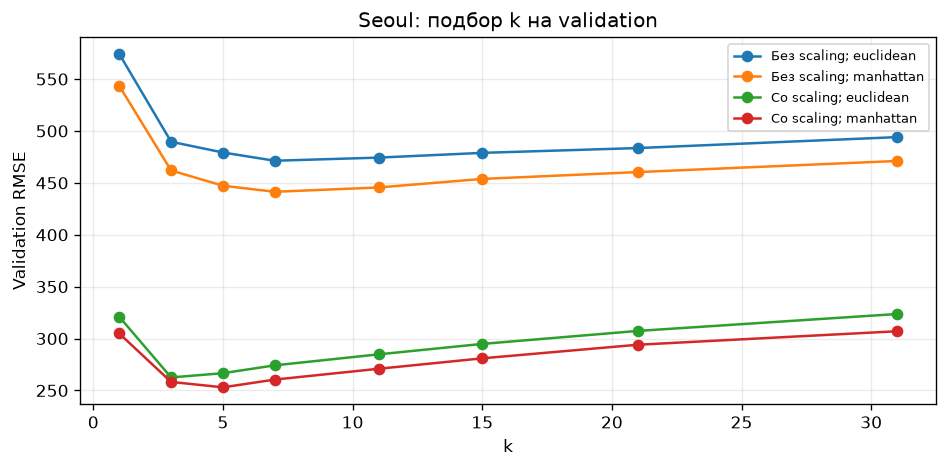

Выбрано по validation: ('Со scaling', 'manhattan') k = 5


In [40]:
seoul_models, seoul_validation_results, seoul_winner = select_knn(
    seoul_feature_sets, seoul_train_targets, seoul_validation_targets, task="regression")
display(seoul_validation_results.round(3))
plot_knn_validation(seoul_validation_results, "RMSE", "Seoul: подбор k на validation")
print("Выбрано по validation:", seoul_winner, "k =", seoul_models[seoul_winner].k)


In [41]:
seoul_results = []
seoul_test_predictions = {}
for (scaling, distance), model in seoul_models.items():
    predictions = model.predict(seoul_feature_sets[scaling][2])
    seoul_test_predictions[(scaling, distance)] = predictions
    validation_row = seoul_validation_results[
        (seoul_validation_results["Scaling"] == scaling)
        & (seoul_validation_results["Distance"] == distance)
        & (seoul_validation_results["k"] == model.k)].iloc[0]
    seoul_results.append({"Scaling": scaling, "Distance": distance, "k": model.k,
                          "Validation RMSE": validation_row["RMSE"],
                          **regression_metrics(seoul_test_targets, predictions)})

seoul_baseline_predictions = np.full(len(seoul_test_targets), seoul_train_targets.mean())
seoul_baseline_metrics = regression_metrics(seoul_test_targets, seoul_baseline_predictions)
seoul_results.append({"Scaling": "Baseline", "Distance": "—", "k": np.nan,
                      "Validation RMSE": root_mean_squared_error(
                          seoul_validation_targets,
                          np.full(len(seoul_validation_targets), seoul_train_targets.mean())),
                      **seoul_baseline_metrics})
seoul_results = pd.DataFrame(seoul_results).set_index(["Scaling", "Distance"])
display(seoul_results.round(3))

print(f"Вывод: по validation выбраны {seoul_winner[0]}, {seoul_winner[1]}, "
      f"k = {seoul_models[seoul_winner].k}. "
      f"Test MAE = {seoul_results.loc[seoul_winner, 'MAE']:.2f}, "
      f"RMSE = {seoul_results.loc[seoul_winner, 'RMSE']:.2f}, "
      f"R^2 = {seoul_results.loc[seoul_winner, 'R^2']:.3f}.")
print(f"Baseline: RMSE = {seoul_baseline_metrics['RMSE']:.2f}, "
      f"разница RMSE baseline − KNN = "
      f"{seoul_baseline_metrics['RMSE'] - seoul_results.loc[seoul_winner, 'RMSE']:.2f}.")
for distance in ["euclidean", "manhattan"]:
    difference = (seoul_results.loc[('Со scaling', distance), 'RMSE']
                  - seoul_results.loc[('Без scaling', distance), 'RMSE'])
    print(f"{distance}: изменение test RMSE после scaling = {difference:+.2f}.")


k  Validation RMSE      MAE     RMSE    R^2
Scaling     Distance                                                
Без scaling euclidean  7.0          471.305  348.727  489.125  0.428
            manhattan  7.0          441.399  326.636  463.604  0.487
Со scaling  euclidean  3.0          262.544  162.545  266.303  0.831
            manhattan  5.0          253.020  163.647  254.678  0.845
Baseline    —          NaN          634.970  524.370  647.112 -0.000

Вывод: по validation выбраны Со scaling, manhattan, k = 5. Test MAE = 163.65, RMSE = 254.68, R^2 = 0.845.
Baseline: RMSE = 647.11, разница RMSE baseline − KNN = 392.43.
euclidean: изменение test RMSE после scaling = -222.82.
manhattan: изменение test RMSE после scaling = -208.93.
